Tomasz Lepszy, *475898*

# Meeting 1 — Real-data baselines

**Where things stand**

| Step | Status | Where |
| --- | --- | --- |
| Train 4 runs × 5 seeds on a Colab T4 | ✅ done | [colab/m1_train.ipynb](../colab/m1_train.ipynb) |
| Validation analysis and choice of `augment()` recipe | ✅ done (strong kept) | sections 4–5, 7.1 |
| Pick the model to test | ✅ `m1-augment-strong` (same in Colab) | section 6.1 |
| Test 3 baselines once | ✅ done | [colab/m1_test.ipynb](../colab/m1_test.ipynb), section 6.2 |
| Test interpretation | ✅ done | section 7.2 |

**Contents**
1. Problem: the task, the question, the expectations
2. The data: what the classifier learns from (plots and photos)
3. What was done: the four runs and how they were produced
4. Validation results
5. Mild vs strong `augment()`
6. Picking the model to test, and the test results
7. Interpretation, conclusion, limitations

This notebook only **reads and analyses**. Training and testing need a GPU and live in `colab/` (shared code: `colab/colab_tools.py`). Run it locally after `git pull`.

### Setup
Moves to the repository root, makes `synthdata` importable and checks that Oxford-IIIT Pet is in `./data` (downloaded once, ~800 MB).

In [80]:
import csv
import itertools
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

here = Path.cwd()
os.chdir(next(p for p in [here, *here.parents] if (p / "pyproject.toml").exists()))
if str(Path("src").resolve()) not in sys.path:
    sys.path.insert(0, str(Path("src").resolve()))

from synthdata import data
from synthdata.config import CLASSES, TARGET

data.download()  # skipped when ./data is already extracted
split = pd.DataFrame([p.__dict__ for p in data.load_split()])
missing = [i for i in split["image"] if not (data.image_path(i).exists() and data.trimap_path(i).exists())]
assert not missing, f"{len(missing)} photos missing from ./data, e.g. {missing[0]}"

ROOT = Path(".")
RUNS_DIR = ROOT / "runs"
EVIDENCE_DIR = ROOT / "evidence"
EVIDENCE_DIR.mkdir(exist_ok=True)
STRONG = "m1-augment-strong"
RUN_NAMES = ["m1-real", "m1-oversample", "m1-augment", STRONG]
COLORS = dict(zip(RUN_NAMES, ["tab:gray", "tab:blue", "tab:orange", "tab:red"]))
print(f"Ready: {Path.cwd()} | {len(split)} course photos")


def save(fig, name):
    """Save a figure to evidence/ and show it."""
    fig.savefig(EVIDENCE_DIR / name, dpi=160)
    plt.show()


Ready: /content/dane_syntetyczne | 905 course photos


## 1. Problem

### 1.1 The task

The course asks one question across all meetings: *can images made by diffusion models improve recognition of Egyptian Mau, an under-represented cat breed, without harming the other seven breeds?* Before any synthetic image can be judged, I need to know what the **classical, real-data ways of fixing class imbalance** achieve. Those results are the baselines every later meeting is compared against.

The experiment is fixed by the course:

| | |
| --- | --- |
| **Data** | 8 cat breeds from Oxford-IIIT Pet (`data/split.csv`) |
| **Imbalance** | 70 training photos per breed, but only **15 for Egyptian Mau** |
| **Validation / test** | 20 / 30 photos per breed (160 / 240 in total) |
| **Budget** | every method adds exactly **55** Egyptian Mau training examples → 15 + 55 = 70, like the other breeds |
| **Classifier** | EfficientNet-B0 pretrained on ImageNet, fine-tuned for 8 epochs |
| **Repetitions** | 5 seeds (0–4) per run |
| **Main metric** | Egyptian Mau **recall**: the share of Mau photos recognised as Mau |
| **Guard metric** | **macro-F1** over all 8 breeds: catches harm to the other breeds |

Egyptian Mau is hard for two reasons: it has 4.7× fewer training photos than every other breed, and it looks like several of them. It's a spotted, silver/bronze short-haired cat, close to **Bengal** (spotted), **Abyssinian** (ticked coat, similar build) and **Russian Blue** (grey).

### 1.2 Question and expectations

> **How much do oversampling and ordinary augmentation help Egyptian Mau recall compared with the imbalanced data?**

Behind it is a more useful question: **why does the model fail on Egyptian Mau?** There are two candidate explanations, and the two methods are designed to separate them:

- **A prior problem.** The model sees Maus 4.7× less often than other breeds, so it learns that "Mau" is a rare answer and avoids it when unsure. Oversampling fixes *only* this: it changes how often the model sees Maus, but adds no new information.
- **A variety problem.** 15 photos show only 15 cats, in 15 poses, on 15 backgrounds. That isn't enough to learn what a Mau looks like in general. Augmentation adds a little artificial variety on top of the balancing. Real new variety is what diffusion models will be tested on in later meetings.

What I expect before running anything:

1. **Imbalanced baseline (`m1-real`):** low Mau recall. With 70 vs 15 photos the model learns a prior towards the large breeds, so uncertain Maus will be pushed into the look-alike breeds.
2. **Oversampling (`m1-oversample`):** clearly higher Mau recall, because the class frequency is balanced. No new information is added, though: the model sees the same 15 photos more often, so it may overfit to them.
3. **Augmentation (`m1-augment`):** at least as good as oversampling, maybe better, because each repeated copy is a slightly different image, which counteracts the overfitting.
4. **Other breeds:** macro-F1 should not drop. If anything it should rise, because fewer Maus would be dumped into other classes.

### 1.3 How I want to solve it

I compare four runs that differ **only** in how the 55 extra Mau examples are made. Everything else (data split, model, epochs, seeds) is identical, so any difference comes from the balancing method:

| Run | Extra Mau examples | Mau examples in training |
| --- | --- | --- |
| `m1-real` | none | 15 |
| `m1-oversample` | 55 exact copies of the 15 photos | 70 |
| `m1-augment` | 55 copies, each randomly transformed every time it is loaded (**mild** transforms) | 70 |
| `m1-augment-strong` | the same, with **stronger** transforms (`augment()` changed once) | 70 |

Each run is trained with 5 seeds so I can tell a real effect from seed-to-seed noise. I compare and decide on the **validation** photos only. The **test** photos are evaluated once, at the end, to report the final numbers.

`m1-augment-strong` answers a follow-up question: *does augmentation help more if the copies differ more?* It uses larger geometric and colour changes and adds hue shifts, grayscale and blur, so it is compared with `m1-augment` on validation (section 5), and the recipe I keep is chosen in section 7.1.

The methods are implemented in `src/synthdata/balance.py`.

#### `oversample()` — repeat the photos evenly

`oversample()` gets the 15 Egyptian Mau training photo names, the seeded `rng`, and `budget = 55`, the number of **extra** examples to add. It repeats the photos as evenly as possible: 55 = 3·15 + 10, so every photo is added 3 times and 10 of them a 4th time. Which 10 get the extra copy is decided by `rng.shuffle()`, so the choice is random but reproducible from the seed. The added copies are pixel-identical to the originals: the model sees each Mau photo more often, but nothing new.

```python
def oversample(minority_photos: list[str], budget: int, rng: random.Random) -> list[str]:
    shuffled = minority_photos.copy()
    rng.shuffle(shuffled)
    base, extra = divmod(budget, len(shuffled))  # 55 = 3 * 15 + 10
    result = []
    for i, photo in enumerate(shuffled):
        result.extend([photo] * (base + (1 if i < extra else 0)))
    return result
```

#### `augment()` — repeat the photos, but make every copy different

The 55 copies are chosen the same way as in oversampling. The difference is that `augment()` is called **every time** a copy is loaded, so each epoch sees a new random variant of the same 15 photos. The **mild** recipe imitates nuisance variation that a real photo of the same cat could have:

- **Horizontal flip** (p = 0.5): a cat facing left is the same breed facing right.
- **One random affine transform**: rotation ±15°, translation ±10%, zoom 0.9–1.1×: a tilted camera, a cat that isn't centred, a slightly different distance. Corners exposed by the rotation are filled with the ImageNet mean grey, not black.
- **Colour jitter** (brightness and contrast ±20%, saturation ±15%): different lighting and cameras.

Deliberately left out of the mild recipe:
- **Hue shifts, grayscale** and strong colour changes: coat colour and the spot pattern are what separates Egyptian Mau from Bengal, Abyssinian and Russian Blue.
- **Vertical flips:** they produce unrealistic images.
- **Large shifts and zooms:** they can push the cat out of the frame.

##### Two sets of transformations

`augment()` was changed once, from the **mild** recipe to a **strong** one. The strong recipe makes every mild change larger **and** adds exactly the changes the mild recipe leaves out on purpose: hue shifts, grayscale and blur.

| | mild (`m1-augment`) | strong (`m1-augment-strong`) |
| --- | --- | --- |
| Flip | horizontal, p = 0.5 | horizontal, p = 0.5 |
| Rotation | ±15° | ±35° |
| Translation | ±10% | ±20% |
| Zoom | 0.9–1.1× | 0.7–1.3× |
| Brightness / contrast / saturation | ±20% / ±20% / ±15% | ±40% / ±40% / ±40% |
| Hue | unchanged | ±0.1 |
| Grayscale | never | p = 0.2 |
| Gaussian blur | never | p = 0.3 (kernel 5, σ 0.5–2) |

**Hypothesis before training** (also written in `balance.py`): the strong recipe gives **no gain or a loss** in Egyptian Mau recall compared with the mild one.

- *Why it made sense.* The spotted silver coat is what separates a Mau from its look-alikes: Bengal (spotted, but warmer colours), Abyssinian (ticked bronze coat, no spots) and Russian Blue (plain grey, no spots). Hue shifts and grayscale change exactly that colour, blur softens the spots, and ±20% shifts combined with up to 1.3× zoom can push part of the cat out of the frame. Training on such copies could teach the model that a cat without the Mau colour or without visible spots is still a Mau, and pull the look-alikes towards "Mau".
- *What would support it:* strong recall at or below mild on most seeds, or more Bengals, Abyssinians or Russian Blues called "Mau".
- *What would refute it:* strong recall above mild on most seeds, without a matching rise in other breeds called "Mau".

The strong run was meant to show that augmentation must preserve the class signal. Section 7.1 shows the second outcome: the hypothesis is refuted.

Both recipes live in `balance.py`, and the environment variable `SYNTHDATA_AUGMENT` (`mild` by default) chooses one, so both runs stay reproducible from the code:

```python
GREY = (124, 116, 104)  # ImageNet mean colour, so rotated corners are not black

AUGMENTS = {
    "mild": transforms.Compose([
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomAffine(degrees=15, translate=(0.1, 0.1), scale=(0.9, 1.1), fill=GREY),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.15),
    ]),
    "strong": transforms.Compose([
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomAffine(degrees=35, translate=(0.2, 0.2), scale=(0.7, 1.3), fill=GREY),
        transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.1),
        transforms.RandomGrayscale(p=0.2),
        transforms.RandomApply([transforms.GaussianBlur(5, sigma=(0.5, 2.0))], p=0.3),
    ]),
}
VARIANT = os.environ.get("SYNTHDATA_AUGMENT", "mild")

def augment(image: Image.Image) -> Image.Image:
    return AUGMENTS[VARIANT](image)
```

After `augment()`, every training image (original or copy) also goes through the pipeline's own `TRAIN_TRANSFORM` in `train.py`: random crop of 75–100%, horizontal flip, and colour jitter of ±15%. The images the network receives under each recipe are shown at the start of section 5.

## 2. The data

Before looking at any model: what exactly does the classifier learn from? `data/split.csv` fixes the course split; every run uses the same photos.

### 2.1 How many photos per breed

role,train,val,test
breed,,,
Abyssinian,70,20,30
Bengal,70,20,30
Birman,70,20,30
Bombay,70,20,30
Egyptian Mau,15,20,30
Ragdoll,70,20,30
Russian Blue,70,20,30
Siamese,70,20,30


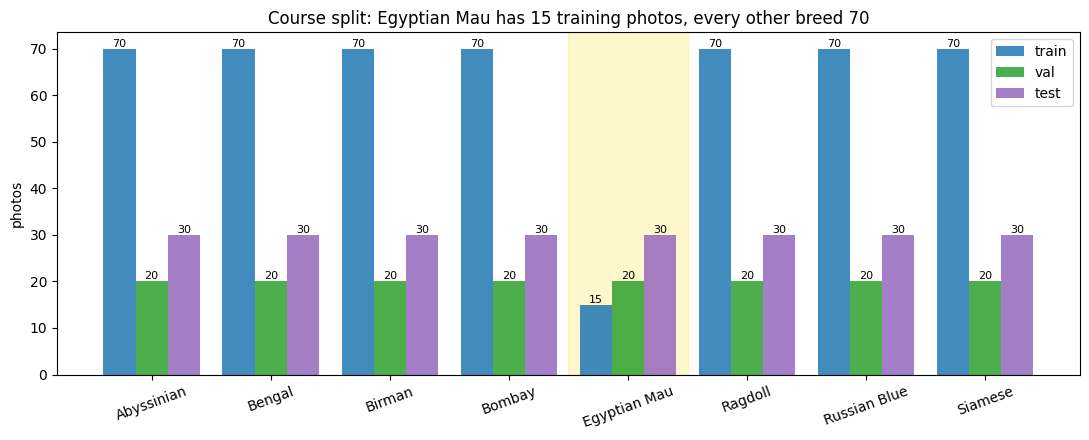

In [81]:
counts = pd.crosstab(split["breed"], split["role"]).reindex(index=CLASSES, columns=["train", "val", "test"])
display(counts)

fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(CLASSES))
for k, (role, color) in enumerate(zip(counts.columns, ["tab:blue", "tab:green", "tab:purple"])):
    bars = ax.bar(x + (k - 1) * 0.27, counts[role], 0.27, label=role, color=color, alpha=0.85)
    ax.bar_label(bars, fontsize=8)
ax.axvspan(CLASSES.index(TARGET) - 0.5, CLASSES.index(TARGET) + 0.5, color="gold", alpha=0.2, zorder=0)
ax.set_xticks(x, CLASSES, rotation=20)
ax.set_ylabel("photos")
ax.set_title("Course split: Egyptian Mau has 15 training photos, every other breed 70")
ax.legend()
fig.tight_layout()
save(fig, "meeting1-data-split.png")

The only imbalance is in **training**: 15 Mau photos against 70 for every other breed. Validation (20 per breed) and test (30 per breed) are balanced, so recall and macro-F1 are directly comparable across breeds.

### 2.2 What the breeds look like

Three random training photos per breed. Egyptian Mau's look-alikes are Bengal (spotted), Abyssinian (ticked coat, similar build) and Russian Blue (grey).

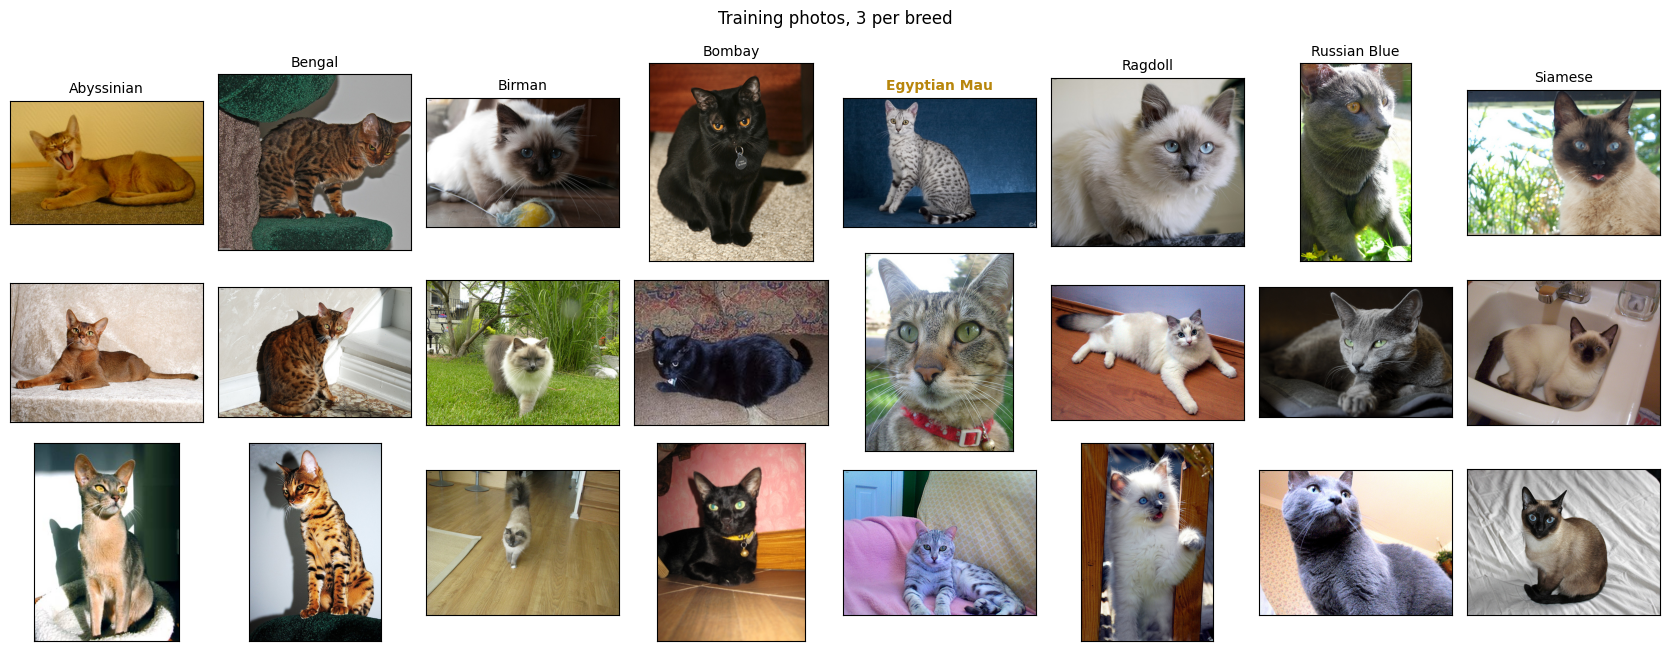

In [82]:
rng = np.random.default_rng(0)
train = split[split["role"] == "train"]
fig, axes = plt.subplots(3, len(CLASSES), figsize=(2.1 * len(CLASSES), 6.6))
for col, breed in enumerate(CLASSES):
    names = rng.choice(train.loc[train["breed"] == breed, "image"].to_numpy(), 3, replace=False)
    for row, name in enumerate(names):
        ax = axes[row, col]
        ax.imshow(data.open_rgb(data.image_path(name)))
        ax.set_xticks([]); ax.set_yticks([])
        if row == 0:
            ax.set_title(breed, fontsize=10, fontweight="bold" if breed == TARGET else None,
                         color="darkgoldenrod" if breed == TARGET else "black")
fig.suptitle("Training photos, 3 per breed")
fig.tight_layout()
save(fig, "meeting1-data-breeds.png")

### 2.3 All 15 Egyptian Mau training photos

Everything any balancing method can use. Oversampling repeats these, `augment()` transforms them, and later meetings generate from them.

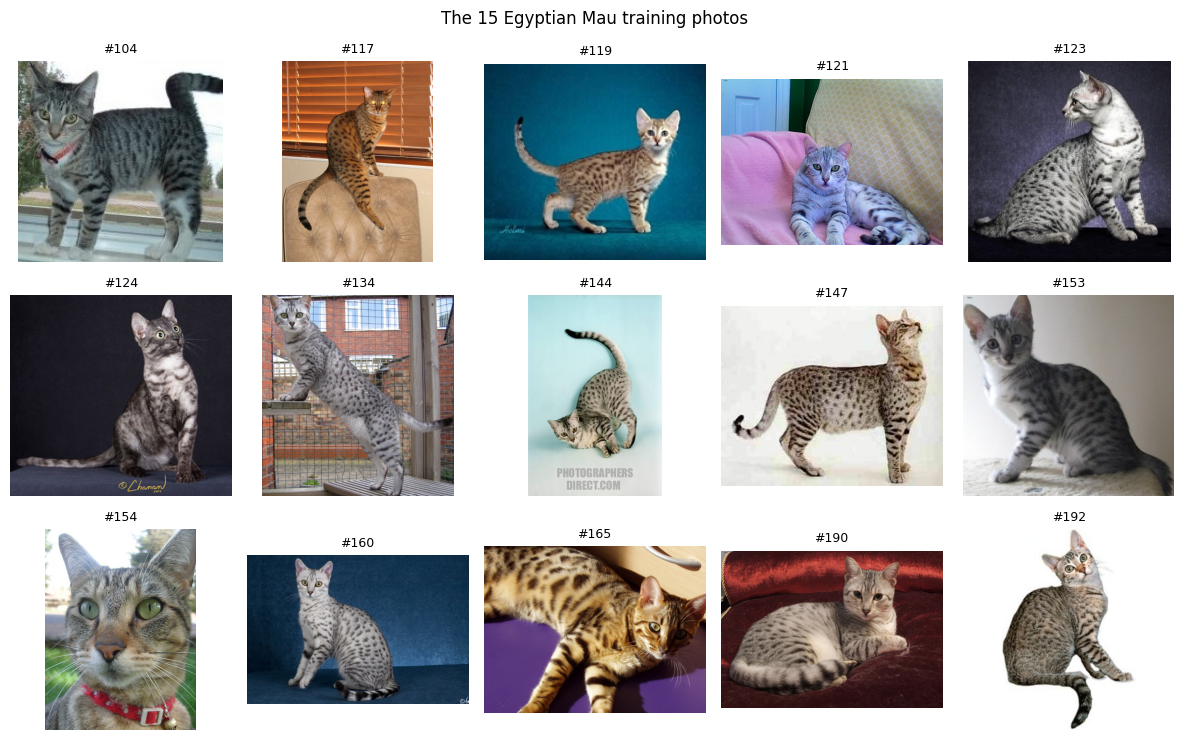

In [83]:
mau_train = data.minority_training_photos()
fig, axes = plt.subplots(3, 5, figsize=(12, 7.5))
for ax, name in zip(axes.ravel(), mau_train):
    ax.imshow(data.open_rgb(data.image_path(name)))
    ax.set_title(name.replace("Egyptian_Mau_", "#"), fontsize=9)
    ax.axis("off")
fig.suptitle(f"The {len(mau_train)} Egyptian Mau training photos")
fig.tight_layout()
save(fig, "meeting1-data-mau-train.png")

Most of them are side or three-quarter views of a whole, clearly spotted, silver cat. Keep this in mind for section 4: the validation Maus the models miss are the ones that *don't* look like this.

## 3. What was done

### 3.1 Training
[colab/m1_train.ipynb](../colab/m1_train.ipynb) trained all four runs on a Colab T4 GPU, 5 seeds each (~30 s per seed). For each run it called `synth-train` with these settings:

| Run | `--method` | `SYNTHDATA_AUGMENT` |
| --- | --- | --- |
| `m1-real` | `real` | – |
| `m1-oversample` | `oversample` | – |
| `m1-augment` | `augment` | `mild` |
| `m1-augment-strong` | `augment` | `strong` |

Then it checked every seed was trained on `cuda`, copied `model.pt` to Google Drive and pushed everything else to GitHub. Each `runs/<name>/seed-K/` holds:
- `metrics.json`: recall per breed, macro-F1, accuracy, confusion matrix (from `synthdata.metrics.summary()`)
- `predictions.csv`: the prediction for every validation photo
- `run.json`: the exact training data and device
- `model.pt`: the weights (on Drive, not in git)

### 3.2 Testing
Following the course protocol, the test photos are evaluated **once**, after the validation analysis and the choice of `augment()` recipe. [colab/m1_test.ipynb](../colab/m1_test.ipynb) restores the weights from Drive, runs `synth-test` on `m1-real`, `m1-oversample` and the chosen augment run, and pushes `test-results.json`. Section 6 picks that run and reads the results back.

### 3.3 Helpers for the analysis

In [84]:
def load_runs(filename, run_names=None):
    """One row per (run, seed) from runs/<name>/<filename>."""
    records, missing = [], []
    for run_name in run_names or RUN_NAMES:
        path = RUNS_DIR / run_name / filename
        if not path.exists():
            missing.append(run_name)
            continue
        for seed in json.loads(path.read_text())["seeds"]:
            records.append({"run": run_name, "seed": seed["seed"],
                            "egyptian_mau_recall": seed["egyptian_mau_recall"],
                            "macro_f1": seed["macro_f1"], "accuracy": seed["accuracy"]})
    if missing:
        print(f"No {filename} yet for:", ", ".join(missing))
    return pd.DataFrame(records)


def load_breed_recall(filename, run_names=None):
    """One row per (run, seed, breed) with that breed's recall."""
    rows = []
    for run_name in run_names or RUN_NAMES:
        for seed in json.loads((RUNS_DIR / run_name / filename).read_text())["seeds"]:
            for breed, value in seed["recall"].items():
                rows.append({"run": run_name, "seed": seed["seed"], "breed": breed, "recall": value})
    return pd.DataFrame(rows)


def summed_confusion(run_name, filename="metrics.json"):
    """Confusion matrix summed over the 5 seeds (rows = true, columns = predicted)."""
    total, names = None, None
    for k in range(5):
        m = json.loads((RUNS_DIR / run_name / f"seed-{k}" / filename).read_text())
        names = list(m["recall"])
        c = np.array(m["confusion"])
        total = c if total is None else total + c
    return total, names


def summarize(df, run_names=None):
    return (
        df.groupby("run", sort=False)
        .agg(seeds=("seed", "count"),
             recall_mean=("egyptian_mau_recall", "mean"), recall_std=("egyptian_mau_recall", "std"),
             recall_min=("egyptian_mau_recall", "min"), recall_max=("egyptian_mau_recall", "max"),
             macro_f1_mean=("macro_f1", "mean"), macro_f1_std=("macro_f1", "std"),
             accuracy_mean=("accuracy", "mean"))
        .reindex([r for r in run_names or RUN_NAMES if r in set(df["run"])])
        .round(3)
    )


def sign_flip_p(diffs):
    """Exact two-sided paired sign-flip (permutation) test over all 2^n sign patterns."""
    diffs = np.asarray(diffs, dtype=float)
    observed = abs(diffs.mean())
    signs = np.array(list(itertools.product([1, -1], repeat=len(diffs))))
    return float((np.abs((signs * diffs).mean(axis=1)) >= observed - 1e-12).mean())


PAIRS = [("m1-oversample", "m1-real"), ("m1-augment", "m1-real"), ("m1-augment", "m1-oversample")]


def paired_tests(df, pairs=None):
    rows = []
    for metric in ["egyptian_mau_recall", "macro_f1"]:
        wide = df.pivot(index="seed", columns="run", values=metric)
        for a, b in pairs or PAIRS:
            d = wide[a] - wide[b]
            rows.append({"metric": metric, "comparison": f"{a} − {b}",
                         "mean diff": round(d.mean(), 3), "seeds better": int((d > 0).sum()),
                         "seeds equal": int((d == 0).sum()), "seeds worse": int((d < 0).sum()),
                         "p (sign-flip)": round(sign_flip_p(d), 3)})
    return pd.DataFrame(rows)


def plot_metric(df, metric, ylabel, title, output_name, run_names=None, ax=None):
    """Dots = seeds, black bar = mean ± std."""
    run_names = run_names or RUN_NAMES
    fig = None
    if ax is None:
        fig, ax = plt.subplots(figsize=(9, 5))
    for position, run_name in enumerate(run_names):
        values = df.loc[df["run"] == run_name, metric]
        ax.scatter([position] * len(values), values, alpha=0.8, color=COLORS[run_name],
                   label="individual seed" if position == 0 else None)
        ax.errorbar(position, values.mean(), yerr=values.std(ddof=1), fmt="_", color="black",
                    capsize=5, markersize=18, linewidth=2, label="mean ± std" if position == 0 else None)
    ax.set_xticks(range(len(run_names)), run_names, rotation=10)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.25)
    ax.legend()
    if fig:
        fig.tight_layout()
        save(fig, output_name)


def mau_error_table(run_names):
    """Mau row and column of the 5-seed summed confusion matrices."""
    rows = []
    for run_name in run_names:
        matrix, names = summed_confusion(run_name)
        mau = names.index(TARGET)
        for j, name in enumerate(names):
            rows.append({"breed": name, "run": run_name,
                         "Mau predicted as": matrix[mau, j], "predicted as Mau": matrix[j, mau]})
    return pd.DataFrame(rows).pivot(index="breed", columns="run", values=["Mau predicted as", "predicted as Mau"]).reindex(
        columns=pd.MultiIndex.from_product([["Mau predicted as", "predicted as Mau"], run_names]))

## 4. Validation results

This section reports numbers; they are interpreted in section 7.1. 20 validation photos per breed, so one Mau photo = 0.05 recall.

#### Per-seed results

In [85]:
results = load_runs("results.json")
results.pivot(index="seed", columns="run", values=["egyptian_mau_recall", "macro_f1", "accuracy"]).reindex(
    columns=pd.MultiIndex.from_product([["egyptian_mau_recall", "macro_f1", "accuracy"], RUN_NAMES])).round(3)

egyptian_mau_recall                                            macro_f1  \
                 m1-real m1-oversample m1-augment m1-augment-strong  m1-real   
seed                                                                           
0                   0.45          0.70       0.70              0.80    0.860   
1                   0.50          0.60       0.70              0.75    0.869   
2                   0.45          0.65       0.65              0.75    0.861   
3                   0.45          0.75       0.70              0.80    0.855   
4                   0.60          0.75       0.75              0.80    0.877   

                                                accuracy                \
     m1-oversample m1-augment m1-augment-strong  m1-real m1-oversample   
seed                                                                     
0            0.911      0.911             0.912    0.869         0.912   
1            0.859      0.887             0.880    0.875         0.862   
2            0.898      0.904             0.899    0.869         0.900   
3            0.906      0.893             0.918    0.862         0.906   
4            0.899      0.893             0.906    0.881         0.900   

                                   
     m1-augment m1-augment-strong  
seed                               
0         0.912             0.912  
1         0.888             0.881  
2         0.906             0.900  
3         0.894             0.919  
4         0.894             0.906

#### Summary across seeds

In [86]:
summary = summarize(results)
baseline = summary.loc["m1-real"]
summary["recall_vs_real"] = (summary["recall_mean"] - baseline["recall_mean"]).round(3)
summary["macro_f1_vs_real"] = (summary["macro_f1_mean"] - baseline["macro_f1_mean"]).round(3)
summary

,seeds,recall_mean,recall_std,recall_min,recall_max,macro_f1_mean,macro_f1_std,accuracy_mean,recall_vs_real,macro_f1_vs_real
run,,,,,,,,,,
m1-real,5,0.49,0.065,0.45,0.60,0.865,0.009,0.871,0.00,0.000
m1-oversample,5,0.69,0.065,0.60,0.75,0.894,0.020,0.896,0.20,0.029
m1-augment,5,0.70,0.035,0.65,0.75,0.897,0.010,0.899,0.21,0.032
m1-augment-strong,5,0.78,0.027,0.75,0.80,0.903,0.015,0.904,0.29,0.038


#### Egyptian Mau recall and macro-F1
Each dot is one seed; the black bar is mean ± 1 std over the 5 seeds.

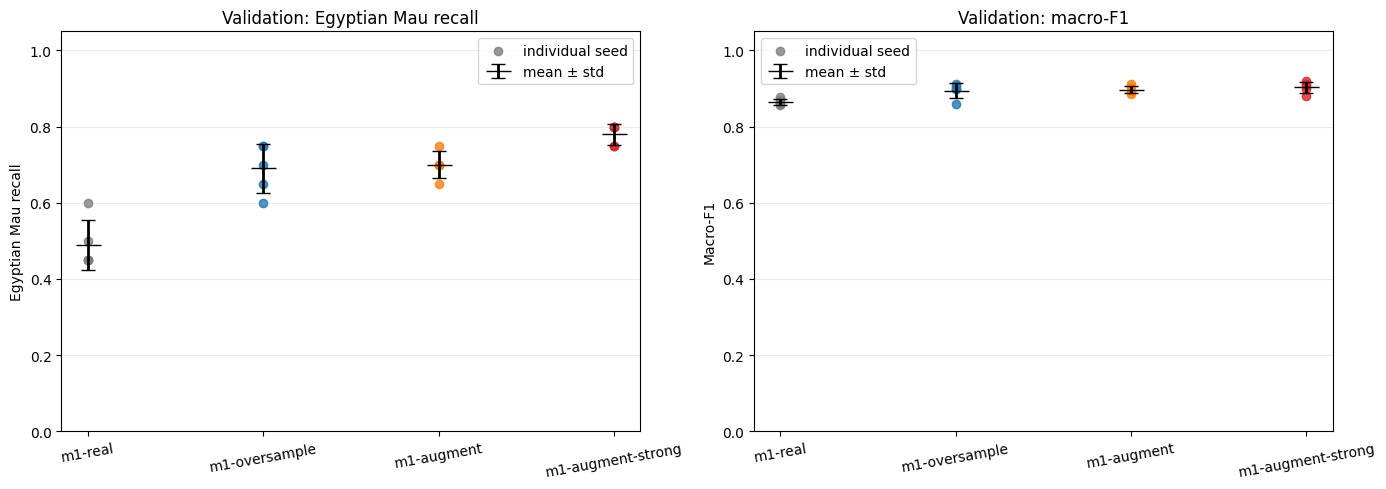

In [87]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_metric(results, "egyptian_mau_recall", "Egyptian Mau recall", "Validation: Egyptian Mau recall", None, ax=axes[0])
plot_metric(results, "macro_f1", "Macro-F1", "Validation: macro-F1", None, ax=axes[1])
fig.tight_layout()
save(fig, "meeting1-validation-recall-f1.png")

#### Seed-by-seed differences and significance

Seed *k* of every run starts from the same pretrained weights and the same seed, so the runs can be compared in pairs.

The p-value comes from an exact paired sign-flip (permutation) test. If there were no difference, each seed's difference would be equally likely to be + or −. All 2⁵ = 32 sign patterns are enumerated, and p is the share whose mean is at least as extreme as the observed one (two-sided). With 5 seeds the smallest possible p is 2/32 = 0.0625.

In [88]:
wide = results.pivot(index="seed", columns="run", values=["egyptian_mau_recall", "macro_f1"])
pd.DataFrame({
    f"{metric_label}: {a} − {b}": wide[metric][a] - wide[metric][b]
    for metric, metric_label in [("egyptian_mau_recall", "recall"), ("macro_f1", "F1")]
    for a, b in PAIRS
}).round(3)

,recall: m1-oversample − m1-real,recall: m1-augment − m1-real,recall: m1-augment − m1-oversample,F1: m1-oversample − m1-real,F1: m1-augment − m1-real,F1: m1-augment − m1-oversample
seed,,,,,,
0,0.25,0.25,0.00,0.050,0.050,-0.000
1,0.10,0.20,0.10,-0.010,0.018,0.027
2,0.20,0.20,0.00,0.036,0.042,0.006
3,0.30,0.25,-0.05,0.050,0.037,-0.013
4,0.15,0.15,0.00,0.022,0.015,-0.006


In [89]:
paired_tests(results)

,metric,comparison,mean diff,seeds better,seeds equal,seeds worse,p (sign-flip)
0,egyptian_mau_recall,m1-oversample − m1-real,0.200,5,0,0,0.062
1,egyptian_mau_recall,m1-augment − m1-real,0.210,5,0,0,0.062
2,egyptian_mau_recall,m1-augment − m1-oversample,0.010,1,3,1,1.000
3,macro_f1,m1-oversample − m1-real,0.030,4,0,1,0.125
4,macro_f1,m1-augment − m1-real,0.033,5,0,0,0.062
5,macro_f1,m1-augment − m1-oversample,0.003,2,0,3,0.875


#### Recall of every breed

Validation recall per breed and run. The bar is the mean over the 5 seeds, the error bar ± 1 std, and the dots are individual seeds. Egyptian Mau is highlighted.

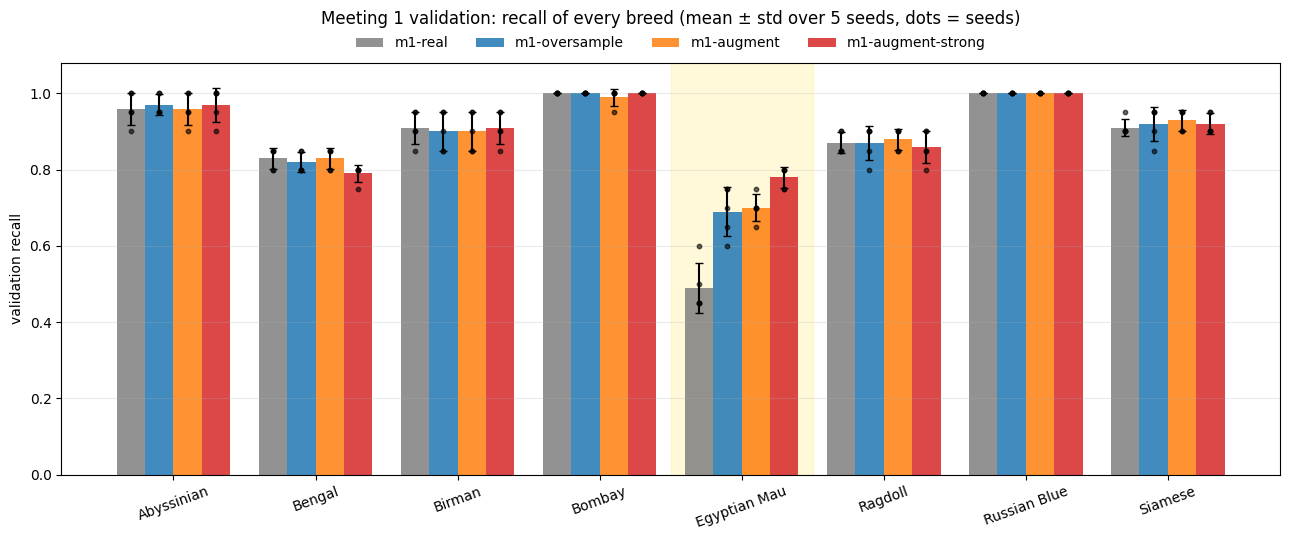

In [90]:
breed_recall = load_breed_recall("results.json")
breeds = list(dict.fromkeys(breed_recall["breed"]))

fig, ax = plt.subplots(figsize=(13, 5.5))
width = 0.8 / len(RUN_NAMES)
for r, run_name in enumerate(RUN_NAMES):
    sub = breed_recall[breed_recall["run"] == run_name]
    stats = sub.groupby("breed")["recall"].agg(["mean", "std"]).reindex(breeds)
    x = np.arange(len(breeds)) + (r - (len(RUN_NAMES) - 1) / 2) * width
    ax.bar(x, stats["mean"], width, yerr=stats["std"], capsize=3, color=COLORS[run_name], alpha=0.85, label=run_name)
    for b, breed in enumerate(breeds):
        values = sub.loc[sub["breed"] == breed, "recall"]
        ax.scatter(np.full(len(values), x[b]), values, s=10, color="black", alpha=0.6, zorder=3)
mau = breeds.index("Egyptian Mau")
ax.axvspan(mau - 0.5, mau + 0.5, color="gold", alpha=0.15, zorder=0)
ax.set_xticks(range(len(breeds)), breeds, rotation=20)
ax.set_ylim(0, 1.08)
ax.set_ylabel("validation recall")
ax.set_title("Meeting 1 validation: recall of every breed (mean ± std over 5 seeds, dots = seeds)", pad=28)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=len(RUN_NAMES), frameon=False)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
save(fig, "meeting1-validation-per-breed-recall.png")

#### Per-breed precision and recall

From the confusion matrices summed over the 5 seeds. The precision of a breed is the share of photos predicted as that breed that really are that breed.

In [91]:
rows = []
for run_name in RUN_NAMES:
    matrix, names = summed_confusion(run_name)
    tp = np.diag(matrix)
    for i, breed in enumerate(names):
        rows.append({"breed": breed, "run": run_name,
                     "precision": tp[i] / matrix[:, i].sum() if matrix[:, i].sum() else 0.0,
                     "recall": tp[i] / matrix[i].sum()})
per_breed = pd.DataFrame(rows).pivot(index="breed", columns="run", values=["precision", "recall"])
per_breed.reindex(columns=pd.MultiIndex.from_product([["precision", "recall"], RUN_NAMES])).round(2)

precision                                             recall  \
               m1-real m1-oversample m1-augment m1-augment-strong m1-real   
breed                                                                       
Abyssinian        0.79          0.82       0.82              0.82    0.96   
Bengal            0.75          0.86       0.86              0.90    0.83   
Birman            0.84          0.87       0.87              0.84    0.91   
Bombay            0.99          0.98       0.99              0.99    1.00   
Egyptian Mau      0.96          0.92       0.92              0.90    0.49   
Ragdoll           0.84          0.85       0.85              0.87    0.87   
Russian Blue      0.88          0.90       0.90              0.93    1.00   
Siamese           1.00          1.00       1.00              1.00    0.91   

                                                         
             m1-oversample m1-augment m1-augment-strong  
breed                                                    
Abyssinian            0.97       0.96              0.97  
Bengal                0.82       0.83              0.79  
Birman                0.90       0.90              0.91  
Bombay                1.00       0.99              1.00  
Egyptian Mau          0.69       0.70              0.78  
Ragdoll               0.87       0.88              0.86  
Russian Blue          1.00       1.00              1.00  
Siamese               0.92       0.93              0.92

#### Confusion matrices

Validation predictions summed over the 5 seeds (each row = 20 photos × 5 seeds = 100 predictions). Each row is normalised, so the diagonal is the per-breed recall.

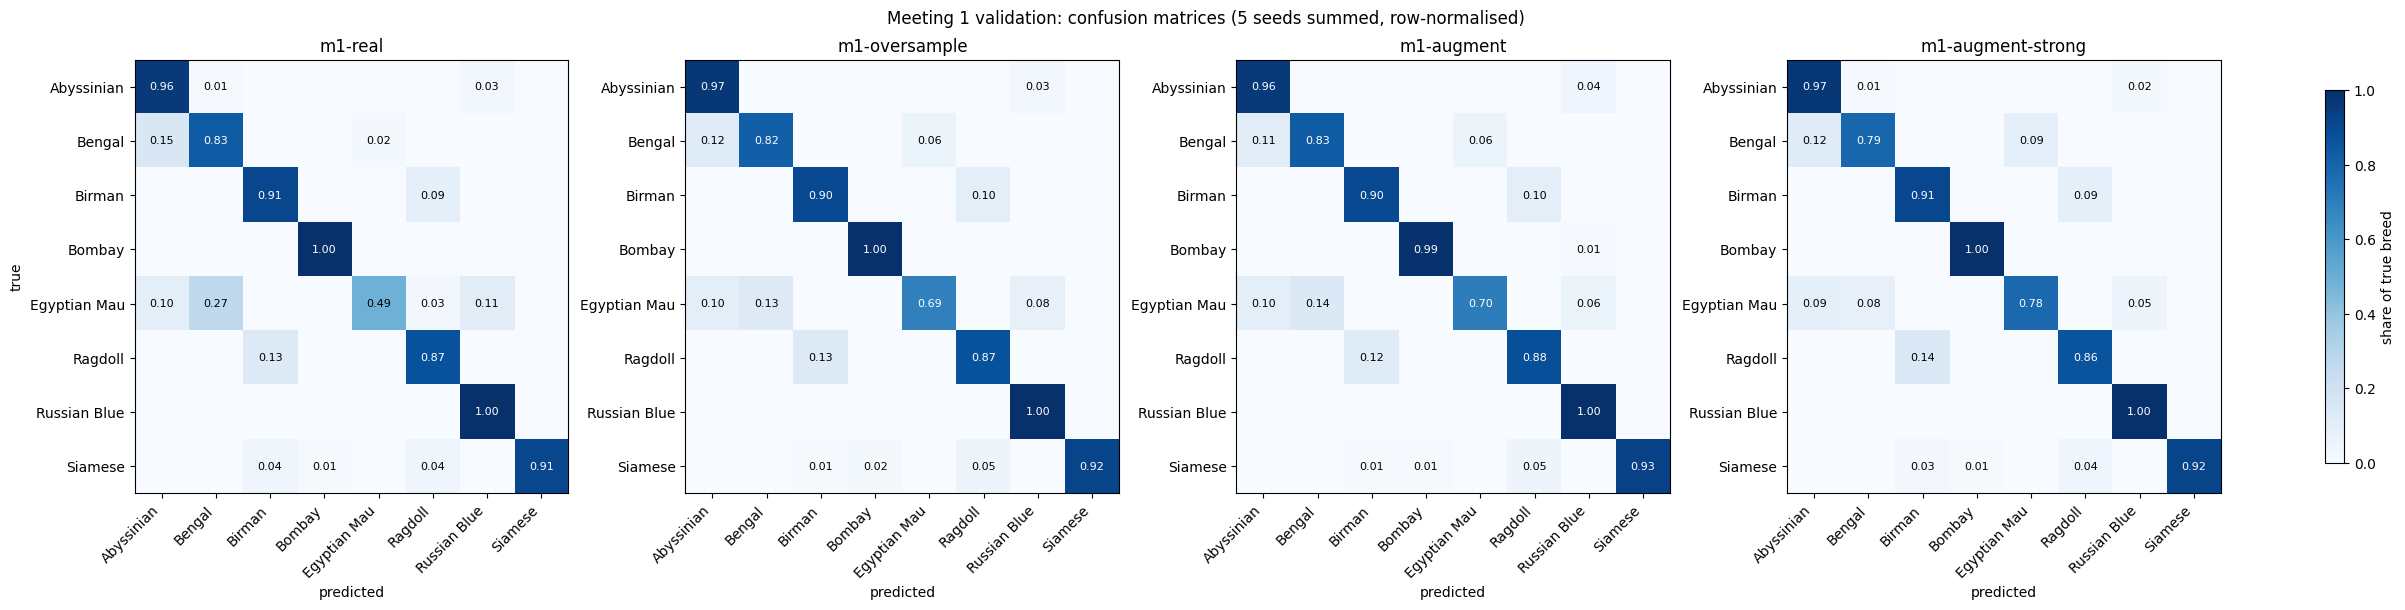

In [92]:
fig, axes = plt.subplots(1, len(RUN_NAMES), figsize=(6 * len(RUN_NAMES), 6), constrained_layout=True)
for ax, run_name in zip(axes, RUN_NAMES):
    matrix, names = summed_confusion(run_name)
    norm = matrix / matrix.sum(axis=1, keepdims=True)
    im = ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(names)):
        for j in range(len(names)):
            if matrix[i, j]:
                ax.text(j, i, f"{norm[i, j]:.2f}", ha="center", va="center", fontsize=8,
                        color="white" if norm[i, j] > 0.5 else "black")
    ax.set_xticks(range(len(names)), names, rotation=45, ha="right")
    ax.set_yticks(range(len(names)), names)
    ax.set_xlabel("predicted")
    ax.set_title(run_name)
axes[0].set_ylabel("true")
fig.colorbar(im, ax=axes, shrink=0.8, label="share of true breed")
fig.suptitle("Meeting 1 validation: confusion matrices (5 seeds summed, row-normalised)")
save(fig, "meeting1-validation-confusion.png")

#### Where the Egyptian Mau errors go

Raw counts from the summed confusion matrices: what the 100 validation Mau predictions per run were classified as, and which other breeds were wrongly predicted as Mau.

In [93]:
mau_error_table(RUN_NAMES)

Mau predicted as                                             \
                      m1-real m1-oversample m1-augment m1-augment-strong   
breed                                                                      
Abyssinian                 10            10         10                 9   
Bengal                     27            13         14                 8   
Birman                      0             0          0                 0   
Bombay                      0             0          0                 0   
Egyptian Mau               49            69         70                78   
Ragdoll                     3             0          0                 0   
Russian Blue               11             8          6                 5   
Siamese                     0             0          0                 0   

             predicted as Mau                                             
                      m1-real m1-oversample m1-augment m1-augment-strong  
breed                                                                     
Abyssinian                  0             0          0                 0  
Bengal                      2             6          6                 9  
Birman                      0             0          0                 0  
Bombay                      0             0          0                 0  
Egyptian Mau               49            69         70                78  
Ragdoll                     0             0          0                 0  
Russian Blue                0             0          0                 0  
Siamese                     0             0          0                 0

#### Which validation Maus are missed

Recall counts photos, so it is worth looking at *which* photos. Each of the 20 validation Maus is judged by 5 models per run; the table counts in how many of the 5 it was **not** recognised, for the photos missed at least once.

In [94]:
ALL_RUNS = RUN_NAMES
rows = []
for run_name in ALL_RUNS:
    for k in range(5):
        with open(RUNS_DIR / run_name / f"seed-{k}" / "predictions.csv") as stream:
            for r in csv.DictReader(stream):
                if r["breed"] == "Egyptian Mau":
                    rows.append({"photo": r["image"], "run": run_name, "predicted": r["predicted"]})
mau_preds = pd.DataFrame(rows)
wrong = mau_preds[mau_preds["predicted"] != "Egyptian Mau"]
missed = wrong.groupby(["photo", "run"]).size().unstack(fill_value=0).reindex(columns=ALL_RUNS, fill_value=0)
missed["total of 20"] = missed.sum(axis=1)
missed["mistaken for"] = wrong.groupby("photo")["predicted"].agg(lambda s: ", ".join(s.value_counts().index))
missed = missed.sort_values("total of 20", ascending=False)
never = 20 - len(missed)
print(f"{never} of 20 validation Maus are recognised by all 20 models; "
      f"{(missed['total of 20'] == 20).sum()} are missed by all 20.")
missed

8 of 20 validation Maus are recognised by all 20 models; 3 are missed by all 20.


run,m1-real,m1-oversample,m1-augment,m1-augment-strong,total of 20,mistaken for
photo,,,,,,
Egyptian_Mau_15,5,5,5,5,20,"Abyssinian, Bengal"
Egyptian_Mau_155,5,5,5,5,20,Abyssinian
Egyptian_Mau_131,5,5,5,5,20,Bengal
Egyptian_Mau_152,5,3,4,4,16,Russian Blue
Egyptian_Mau_171,5,5,5,1,16,Bengal
Egyptian_Mau_148,5,3,3,2,13,"Bengal, Russian Blue"
Egyptian_Mau_11,5,3,1,0,9,Russian Blue
Egyptian_Mau_110,4,1,2,0,7,Bengal
Egyptian_Mau_157,5,1,0,0,6,"Ragdoll, Russian Blue, Bengal"


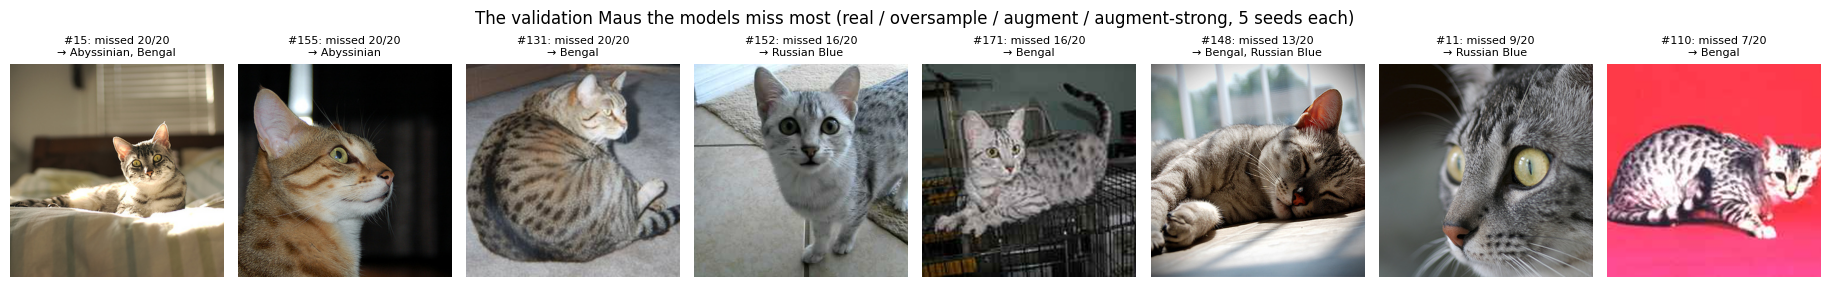

In [95]:
from synthdata import inputs

shown = missed.index[:8]
fig, axes = plt.subplots(1, len(shown), figsize=(2.3 * len(shown), 3))
for ax, name in zip(axes, shown):
    ax.imshow(inputs.source_photo(name))
    row = missed.loc[name]
    ax.set_title(f"{name.replace('Egyptian_Mau_', '#')}: missed {row['total of 20']}/20\n→ {row['mistaken for']}", fontsize=8)
    ax.axis("off")
fig.suptitle("The validation Maus the models miss most (real / oversample / augment / augment-strong, 5 seeds each)")
fig.tight_layout()
save(fig, "meeting1-validation-hard-maus.png")

## 5. Mild vs strong `augment()` (validation)

`m1-augment-strong` differs from `m1-augment` **only** in the transform applied to the 55 added copies (section 1.3): same copies per seed, model, epochs, seeds and machine.

First, what the network actually receives for one Mau photo: each added copy goes through `augment()` and then through the pipeline's own crop, flip and jitter (`TRAIN_TRANSFORM`), which every training image gets.

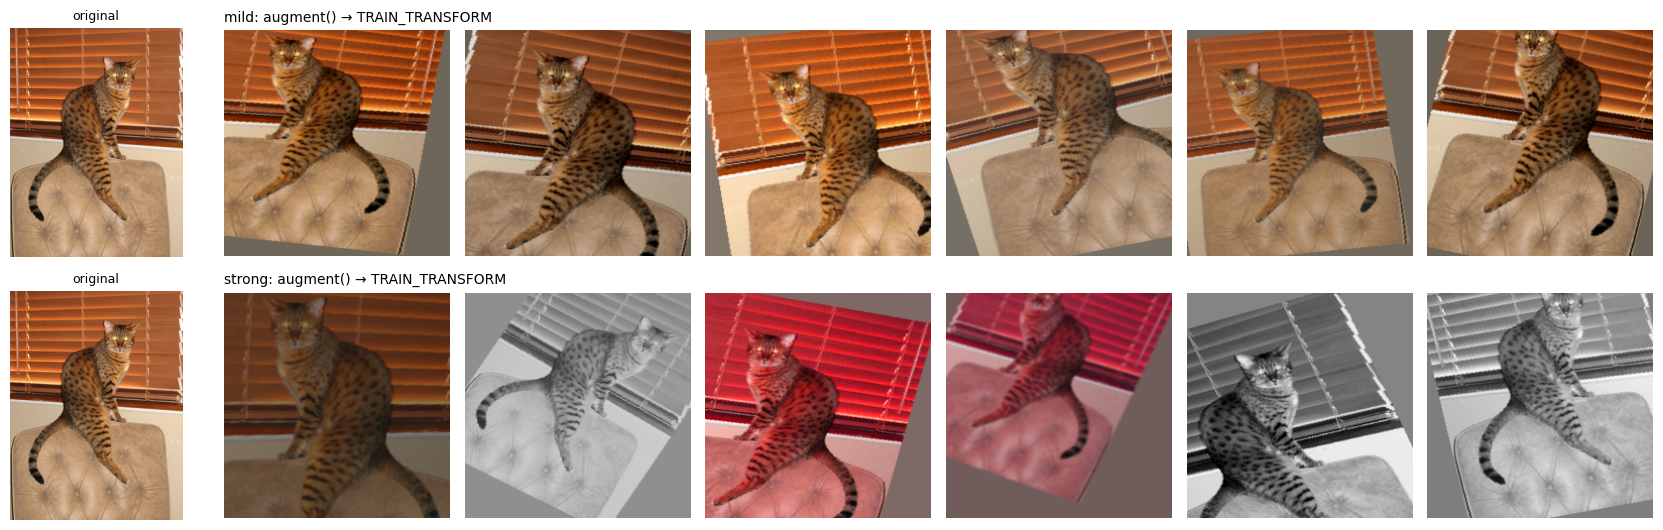

In [96]:
import torch
from synthdata import balance, data
from synthdata import train as T

photo = T.load_small(data.image_path("Egyptian_Mau_117"))
mean, std = torch.tensor(T.MEAN)[:, None, None], torch.tensor(T.STD)[:, None, None]
torch.manual_seed(0)

fig, axes = plt.subplots(2, 7, figsize=(17, 5.4))
for row, name in enumerate(["mild", "strong"]):
    axes[row, 0].imshow(photo)
    axes[row, 0].set_title("original", fontsize=9)
    for k in range(1, 7):
        x = T.TRAIN_TRANSFORM(balance.AUGMENTS[name](photo.copy()))
        axes[row, k].imshow((x * std + mean).clamp(0, 1).permute(1, 2, 0).numpy())
    axes[row, 1].set_title(f"{name}: augment() → TRAIN_TRANSFORM", loc="left", fontsize=10)
for ax in axes.ravel():
    ax.axis("off")
fig.tight_layout()
save(fig, "meeting1-augment-mild-vs-strong.png")

#### Per-seed results and significance
`m1-oversample` is included as the no-transform reference.

In [97]:
AUG_RUNS = ["m1-oversample", "m1-augment", STRONG]
aug_results = load_runs("results.json", AUG_RUNS)
aug_results.pivot(index="seed", columns="run", values=["egyptian_mau_recall", "macro_f1"]).reindex(
    columns=pd.MultiIndex.from_product([["egyptian_mau_recall", "macro_f1"], AUG_RUNS])).round(3)

egyptian_mau_recall                                   macro_f1  \
           m1-oversample m1-augment m1-augment-strong m1-oversample   
seed                                                                  
0                   0.70       0.70              0.80         0.911   
1                   0.60       0.70              0.75         0.859   
2                   0.65       0.65              0.75         0.898   
3                   0.75       0.70              0.80         0.906   
4                   0.75       0.75              0.80         0.899   

                                   
     m1-augment m1-augment-strong  
seed                               
0         0.911             0.912  
1         0.887             0.880  
2         0.904             0.899  
3         0.893             0.918  
4         0.893             0.906

In [98]:
aug_summary = summarize(aug_results, AUG_RUNS)
display(aug_summary)
paired_tests(aug_results, [(STRONG, "m1-augment"), (STRONG, "m1-oversample")])

,seeds,recall_mean,recall_std,recall_min,recall_max,macro_f1_mean,macro_f1_std,accuracy_mean
run,,,,,,,,
m1-oversample,5,0.69,0.065,0.60,0.75,0.894,0.020,0.896
m1-augment,5,0.70,0.035,0.65,0.75,0.897,0.010,0.899
m1-augment-strong,5,0.78,0.027,0.75,0.80,0.903,0.015,0.904


,metric,comparison,mean diff,seeds better,seeds equal,seeds worse,p (sign-flip)
0,egyptian_mau_recall,m1-augment-strong − m1-augment,0.080,5,0,0,0.062
1,egyptian_mau_recall,m1-augment-strong − m1-oversample,0.090,5,0,0,0.062
2,macro_f1,m1-augment-strong − m1-augment,0.006,3,0,2,0.438
3,macro_f1,m1-augment-strong − m1-oversample,0.009,5,0,0,0.062


#### Per-breed recall and where the Mau errors go

In [99]:
aug_breed = load_breed_recall("results.json", AUG_RUNS)
display(aug_breed.groupby(["breed", "run"])["recall"].mean().unstack()[AUG_RUNS].round(2))
mau_error_table(AUG_RUNS)

run,m1-oversample,m1-augment,m1-augment-strong
breed,,,
Abyssinian,0.97,0.96,0.97
Bengal,0.82,0.83,0.79
Birman,0.90,0.90,0.91
Bombay,1.00,0.99,1.00
Egyptian Mau,0.69,0.70,0.78
Ragdoll,0.87,0.88,0.86
Russian Blue,1.00,1.00,1.00
Siamese,0.92,0.93,0.92


Mau predicted as                              predicted as Mau  \
                m1-oversample m1-augment m1-augment-strong    m1-oversample   
breed                                                                         
Abyssinian                 10         10                 9                0   
Bengal                     13         14                 8                6   
Birman                      0          0                 0                0   
Bombay                      0          0                 0                0   
Egyptian Mau               69         70                78               69   
Ragdoll                     0          0                 0                0   
Russian Blue                8          6                 5                0   
Siamese                     0          0                 0                0   

                                           
             m1-augment m1-augment-strong  
breed                                      
Abyssinian            0                 0  
Bengal                6                 9  
Birman                0                 0  
Bombay                0                 0  
Egyptian Mau         70                78  
Ragdoll               0                 0  
Russian Blue          0                 0  
Siamese               0                 0

## 6. Picking the model to test, and the test results

### 6.1 Pick

`m1-real` and `m1-oversample` are always tested. **One** of the two `augment()` runs is tested alongside them, chosen on validation only (reasoning in section 7.1). The table shows the candidates side by side.

To test: set `TEST_AUGMENT` below, set the **same** value as `AUGMENT_RUN` in [colab/m1_test.ipynb](../colab/m1_test.ipynb), run that notebook in Colab, then `git pull` here and re-run from this cell. The cell checks that the two notebooks agree. Once tested, don't change the choice.

In [100]:
TEST_AUGMENT = "m1-augment-strong"  # ← pick: "m1-augment" (mild) or "m1-augment-strong"

CANDIDATES = ["m1-augment", "m1-augment-strong"]
assert TEST_AUGMENT in CANDIDATES, f"pick one of {CANDIDATES}, got {TEST_AUGMENT!r}"
TEST_RUNS = ["m1-real", "m1-oversample", TEST_AUGMENT]

display(summarize(load_runs("results.json", CANDIDATES), CANDIDATES)
        [["recall_mean", "recall_std", "macro_f1_mean", "macro_f1_std"]]
        .assign(picked=lambda d: np.where(d.index == TEST_AUGMENT, "✅", "")))

# the Colab test notebook must test the same run
colab_cells = json.loads(Path("colab/m1_test.ipynb").read_text())["cells"]
colab_src = "".join("".join(c["source"]) for c in colab_cells)
colab_pick = next((r for r in CANDIDATES if f'AUGMENT_RUN = "{r}"' in colab_src), None)
if colab_pick != TEST_AUGMENT:
    print(f"⚠ colab/m1_test.ipynb tests AUGMENT_RUN = {colab_pick!r}, not {TEST_AUGMENT!r}: make them match.")

status = {n: (RUNS_DIR / n / "test-results.json").exists() for n in TEST_RUNS}
HAVE_TEST = all(status.values())
for n, done in status.items():
    print(f"{'✅' if done else '⬜'} {n}: {'tested' if done else 'no test results yet'}")
if not HAVE_TEST:
    print("\nRun colab/m1_test.ipynb in Colab, then `git pull`. Section 6.2 is skipped until then.")

,recall_mean,recall_std,macro_f1_mean,macro_f1_std,picked
run,,,,,
m1-augment,0.70,0.035,0.897,0.010,
m1-augment-strong,0.78,0.027,0.903,0.015,✅


✅ m1-real: tested
✅ m1-oversample: tested
✅ m1-augment-strong: tested


### 6.2 Test results

Evaluated once (240 test photos, 30 per breed, so one Mau photo = 0.033 recall).

#### Per-seed results and summary

In [101]:
if HAVE_TEST:
    test_results = load_runs("test-results.json", TEST_RUNS)
    display(test_results.pivot(index="seed", columns="run", values=["egyptian_mau_recall", "macro_f1"]).reindex(
        columns=pd.MultiIndex.from_product([["egyptian_mau_recall", "macro_f1"], TEST_RUNS])).round(3))
else:
    print("Skipped: no test results yet.")

egyptian_mau_recall                                 macro_f1  \
                 m1-real m1-oversample m1-augment-strong  m1-real   
seed                                                                
0                  0.433         0.667             0.733    0.838   
1                  0.500         0.733             0.700    0.866   
2                  0.467         0.667             0.767    0.864   
3                  0.433         0.700             0.700    0.847   
4                  0.600         0.733             0.767    0.860   

                                      
     m1-oversample m1-augment-strong  
seed                                  
0            0.866             0.887  
1            0.895             0.878  
2            0.882             0.887  
3            0.891             0.899  
4            0.878             0.875

In [102]:
if HAVE_TEST:
    test_summary = summarize(test_results, TEST_RUNS)
    display(test_summary)
else:
    print("Skipped: no test results yet.")

,seeds,recall_mean,recall_std,recall_min,recall_max,macro_f1_mean,macro_f1_std,accuracy_mean
run,,,,,,,,
m1-real,5,0.487,0.069,0.433,0.600,0.855,0.012,0.861
m1-oversample,5,0.700,0.033,0.667,0.733,0.882,0.011,0.883
m1-augment-strong,5,0.733,0.033,0.700,0.767,0.885,0.009,0.886


#### Validation vs test

,val recall,test recall,val macro-F1,test macro-F1
run,,,,
m1-real,0.49,0.487,0.865,0.855
m1-oversample,0.69,0.700,0.894,0.882
m1-augment-strong,0.78,0.733,0.903,0.885


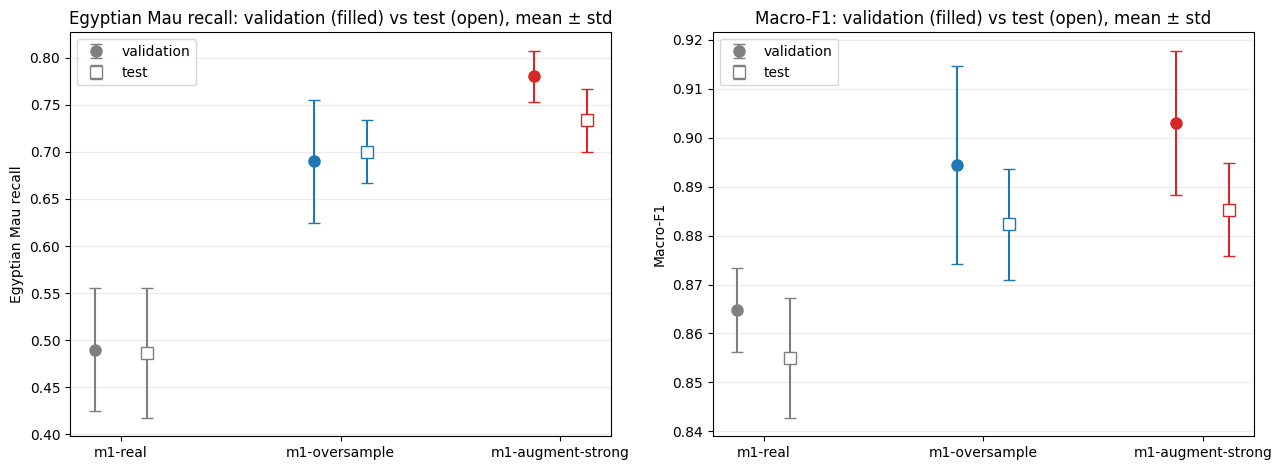

In [103]:
if HAVE_TEST:
    val_results = load_runs("results.json", TEST_RUNS)
    val_summary = summarize(val_results, TEST_RUNS)
    comparison = pd.DataFrame({
        "val recall": val_summary["recall_mean"], "test recall": test_summary["recall_mean"],
        "val macro-F1": val_summary["macro_f1_mean"], "test macro-F1": test_summary["macro_f1_mean"],
    })
    display(comparison)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    for ax, (metric, label) in zip(axes, [("egyptian_mau_recall", "Egyptian Mau recall"), ("macro_f1", "Macro-F1")]):
        for offset, (name, df, marker) in zip([-0.12, 0.12], [("validation", val_results, "o"), ("test", test_results, "s")]):
            for position, run_name in enumerate(TEST_RUNS):
                values = df.loc[df["run"] == run_name, metric]
                ax.errorbar(position + offset, values.mean(), yerr=values.std(ddof=1), fmt=marker,
                            color=COLORS[run_name], mfc="white" if name == "test" else COLORS[run_name],
                            capsize=4, markersize=8, label=name if position == 0 else None)
        ax.set_xticks(range(len(TEST_RUNS)), TEST_RUNS)
        ax.set_ylabel(label)
        ax.set_title(f"{label}: validation (filled) vs test (open), mean ± std")
        ax.grid(axis="y", alpha=0.25)
        ax.legend()
    fig.tight_layout()
    save(fig, "meeting1-val-vs-test.png")
else:
    print("Skipped: no test results yet.")

#### Seed-by-seed significance on test

In [104]:
if HAVE_TEST:
    a, b, c = TEST_RUNS
    display(paired_tests(test_results, [(b, a), (c, a), (c, b)]))
else:
    print("Skipped: no test results yet.")

,metric,comparison,mean diff,seeds better,seeds equal,seeds worse,p (sign-flip)
0,egyptian_mau_recall,m1-oversample − m1-real,0.213,5,0,0,0.062
1,egyptian_mau_recall,m1-augment-strong − m1-real,0.247,5,0,0,0.062
2,egyptian_mau_recall,m1-augment-strong − m1-oversample,0.033,3,1,1,0.375
3,macro_f1,m1-oversample − m1-real,0.027,5,0,0,0.062
4,macro_f1,m1-augment-strong − m1-real,0.030,5,0,0,0.062
5,macro_f1,m1-augment-strong − m1-oversample,0.003,3,0,2,0.625


## 7. Interpretation

### 7.1 Validation (written before the test set is evaluated)

All four runs were trained in Colab on a Tesla T4 (`cuda`), about 30 s per seed.

| Run | Mau recall, seeds 0–4 | Mau recall mean ± std | Macro-F1 mean ± std |
| --- | --- | ---: | ---: |
| `m1-real` | 0.45, 0.50, 0.45, 0.45, 0.60 | 0.49 ± 0.07 | 0.865 ± 0.009 |
| `m1-oversample` | 0.70, 0.60, 0.65, 0.75, 0.75 | 0.69 ± 0.07 | 0.894 ± 0.020 |
| `m1-augment` (mild) | 0.70, 0.70, 0.65, 0.70, 0.75 | 0.70 ± 0.04 | 0.897 ± 0.010 |
| `m1-augment-strong` | 0.80, 0.75, 0.75, 0.80, 0.80 | 0.78 ± 0.03 | 0.903 ± 0.015 |

**Balancing clearly helps Egyptian Mau recall.** Mean recall goes from 0.49 (real) to 0.69 (oversample), 0.70 (mild augment) and 0.78 (strong augment), a gain of +0.20 to +0.29. This isn't seed noise: every seed of every balanced run improves on its baseline seed (by +0.10 to +0.35), and the worst balanced seed (0.60) equals the best baseline seed. All 5 seeds improving is the strongest result 5 seeds can give (sign-flip p = 0.0625, the minimum).

**The baseline's problem is mostly the class prior.** With 15 Mau photos the model avoids the answer "Mau": when it says it, it is almost always right (precision 0.96), but it says it for only half of the Maus. Over 5 seeds, 51 of 100 validation Maus went elsewhere: Bengal (27), Russian Blue (11), Abyssinian (10), Ragdoll (3). Oversampling adds no information, only frequency, and it alone halves the Bengal confusions (27 → 13) and removes the Ragdoll ones.

**The other breeds aren't harmed: macro-F1 rises** from 0.865 to 0.894–0.903 in all three balanced runs. Every other breed keeps its recall within about ±0.02, except Bengal (0.83 → 0.82 → 0.83 → 0.79), because more Bengals are called Mau (2 → 6 → 6 → 9 of 100). Mau precision falls accordingly (0.96 → 0.92 → 0.92 → 0.90), while Bengal precision rises (0.75 → 0.86 → 0.86 → 0.90) because fewer Maus are dumped into it. Balancing moves the Mau/Bengal boundary, and so far the trade is clearly favourable.

**Mild augmentation adds nothing beyond what oversampling already gives.** The two runs have practically the same mean recall (0.70 vs 0.69) and macro-F1 (0.897 vs 0.894); seed by seed, the recall differences are 0, +0.10, 0, −0.05, 0 (p = 1.0). A likely reason is in the training pipeline: every training image already gets a random crop, flip and colour jitter (`TRAIN_TRANSFORM`), so the oversampled copies are never pixel-identical at the model input, and the mild recipe only adds a little more of the same.

**Strong augmentation is the one method that adds something, against my expectation.** I expected the strong recipe to lose (section 1.3), because hue shifts, grayscale and blur damage the coat colour and pattern. Instead `m1-augment-strong` is better than mild on **every** seed (+0.10, +0.05, +0.10, +0.10, +0.05; mean +0.08, p = 0.0625, the minimum), and better than oversampling on every seed too. Its macro-F1 is also the highest (0.903; +0.006 over mild, p = 0.44), so the extra Maus are not bought with harm to the other breeds overall. Counting errors over the 5 seeds: strong misses 22 Maus against mild's 30, mostly fewer Maus called Bengal (14 → 8) and Russian Blue (6 → 5). The cost is 3 more Bengals called "Mau" (6 → 9), so this is a better separation of the two breeds, not only a shifted boundary: +8 Maus for −3 Bengals.

**Where the hypothesis went wrong.** It assumed that distorted copies would *replace* the colour cue with a wrong one. But the distorted copies are only 55 of the 560 training images, the 15 original Mau photos are always shown undistorted, and grayscale hits only about 1 in 5 copies. So the model still learns the real Mau colour from the originals, and the strong copies add something on top instead of overwriting it. Every copy, however distorted, still shows a real Mau's spot pattern and body shape.

**What the strong copies may add: three candidate explanations.** They fit the numbers, but none of them is isolated by these runs, so they are explanations, not proven causes.

1. *Regularization against memorizing the 15 photos.* Over 8 epochs the model can memorize the 15 Mau photos (their background, pose and lighting) instead of learning the breed. Copies that differ a lot make memorizing useless, so the model has to rely on what all copies share: the spots and the shape. Two facts limit this explanation. Oversampling shows the same 15 photos 4.7× more often, which should make memorizing *worse*, yet it gives the biggest gain (+0.20), so memorizing isn't the baseline's main problem; at most it limits the balanced runs. And mild augmentation, which should also reduce memorizing, adds nothing. That only makes sense together with the training pipeline: `TRAIN_TRANSFORM` already gives every image a random crop, flip and ±15% colour jitter, about as much variation as the mild recipe, so only variation *beyond* that level is new.
2. *Less reliance on colour* (a specific form of 1). Hue shifts and grayscale make colour an unreliable cue in the copies, so the model leans more on the spot pattern and the shape. This fits the confusion with Russian Blue, the plain grey breed: Maus called Russian Blue fall 11 → 8 → 6 → 5 (real → oversample → mild → strong), the fewest of all runs.
3. *More framings* (a specific form of 1, for geometry). A 0.7–1.3× zoom, ±20% shifts and ±35° rotation, followed by `TRAIN_TRANSFORM`'s crop, give close-ups and off-centre views that the 15 training photos don't contain. This fits two photos (below): the close-up #11 and the unusually framed #171.

*How they could be told apart (not done here):* train one strong run with only the colour changes (hue, grayscale, blur) and one with only the geometric changes; and log training accuracy, to see whether the oversample and mild runs really memorize the 15 photos (Mau training accuracy near 1.0 while validation recall stays at 0.70).

**The comparison is decided by a handful of photos.** Across all 20 models, 8 of the 20 validation Maus are always recognised and **3 are never recognised**, whatever the method: #15 and #155 are called Abyssinian (19 and 20 of 20 times), and #131 is called Bengal. Two more are missed by every model except the strong ones: #152 (called Russian Blue; strong recovers it once in 5) and #171 (called Bengal; strong recovers it in **4 of 5** seeds, all other runs in 0 of 15). Most of the difference between methods comes from these and a few "swing" photos (#148, #11, #110, #157) that the baseline misses and the balanced runs sometimes recover. The best seed of any method reaches **0.80 recall** on validation.

The photos show what the hard cases have in common: the **spotted coat isn't visible in the usual way**. #15 is a small cat far away on a bed; #155 is a head-and-shoulders portrait of a bronze cat; #11 is an extreme close-up of a face; #152 is a grey cat seen from the front; #131 is curled up, seen from above; #171 lies on top of a wire cage against a cluttered background. The 15 training photos are mostly side views of a whole, clearly spotted, silver cat. These are also the same photos that sat closest to another breed's prototype in the frozen-backbone analysis of [meeting0.ipynb](meeting0.ipynb) (section 2.6), before any training.

Two photos support explanation 3, "more framings": #11, the extreme close-up, is recognised by 0 / 2 / 4 / 5 of 5 models (real / oversample / mild / strong), increasing with the amount of zoom; and #171, a cat in an unusual setting, is recovered only by the strong recipe. Two photos are weak evidence, but the pattern is consistent.

**Which `augment()` to keep.** Unlike in my expectation, the decision is easy:

- for **strong** (`m1-augment-strong`): highest Mau recall (0.78 vs 0.70), better than mild on all 5 seeds; highest macro-F1 (0.903); fewest Maus lost to Bengal and Russian Blue.
- for **mild** (`m1-augment`): Bengal recall stays at the oversampling level (0.83 vs 0.79), and only 6 Bengals per 100 are called Mau instead of 9.

> **Decision:** I keep the **strong** recipe, `m1-augment-strong`. It has the highest Egyptian Mau recall (0.78 vs 0.70), the main metric, and is better than the mild recipe on every seed (p = 0.0625, the smallest p 5 seeds allow). Its macro-F1 is the highest of all runs, so the gain isn't paid for by the other breeds overall. The known cost is that 3 more Bengals per 100 are called Mau and Bengal recall drops to 0.79; that is the number to watch on the test photos and in every later meeting. The choice is made on the same 20 validation Maus that show the gain, so the test value is the honest estimate.

The kept recipe becomes the augment baseline that is tested and that every later meeting is compared with.

### 7.2 Test

The three runs chosen on validation were evaluated once, by [colab/m1_test.ipynb](../colab/m1_test.ipynb) on a Colab T4: 15 saved models (3 runs × 5 seeds) on the 240 test photos, 30 per breed, so one Mau photo = 0.033 recall. Mild `m1-augment` was not tested, so the mild-vs-strong comparison exists only on validation.

| Run | Mau recall, test seeds 0–4 | Mau recall val → **test** | Macro-F1 val → **test** |
| --- | --- | ---: | ---: |
| `m1-real` | 0.43, 0.50, 0.47, 0.43, 0.60 | 0.49 → **0.49** ± 0.07 | 0.865 → **0.855** ± 0.012 |
| `m1-oversample` | 0.67, 0.73, 0.67, 0.70, 0.73 | 0.69 → **0.70** ± 0.03 | 0.894 → **0.882** ± 0.011 |
| `m1-augment-strong` | 0.73, 0.70, 0.77, 0.70, 0.77 | 0.78 → **0.73** ± 0.03 | 0.903 → **0.885** ± 0.009 |

**Balancing holds on test.** Oversampling adds +0.21 Mau recall and strong augmentation +0.25 over the baseline, better on all 5 seeds for both (p = 0.0625, the minimum); macro-F1 also rises on all 5 seeds for both (+0.027 and +0.030). The baseline's diagnosis repeats exactly: on test it never wrongly says "Mau" (precision 1.00) but finds only half of the Maus (0.49).

**Strong augmentation's lead mostly disappears.** On validation strong beat oversampling by +0.09; on test by +0.03, with 3 seeds better, 1 equal and 1 worse (p = 0.375), and macro-F1 is practically the same (+0.003, p = 0.625). The baseline and oversampling barely move between validation and test, but strong falls by 0.05. That is the regression 7.4 warned about: the recipe was chosen on the same 20 validation Maus that showed its gain, so part of that gain was luck on those photos. Strong is still the best run on test, but no longer clearly better than oversampling.

**One of the three explanations carries over: less reliance on colour.** Maus called Russian Blue, the plain grey breed, fall 25 → 16 → 10 of 150 predictions (real → oversample → strong), the same steady fall as on validation and the clearest strong-specific effect on test. Maus called Bengal halve with balancing (48 → 23) but strong adds nothing there (23 → 23).

**The cost at the Bengal boundary is small.** Bengals called "Mau" go 0 → 1 → 4 of 150, Bengal recall 0.92 → 0.90 → 0.89, and Mau precision 1.00 → 0.99 → 0.95. The cost seen on validation is real, but smaller on test.

**The test set has its own hard Maus.** 7 of the 30 test Maus are missed by all 15 models: #47, #58, #84 and #215 are called Bengal, #69 Abyssinian, and #51 and #70 Russian Blue. So no method here can exceed 23 / 30 = **0.77** test recall, and strong's best seeds reach exactly that. Only 11 of the 30 are recognised by every model; the methods differ on the remaining 12.

**Validation vs test, in short:** the ranking is the same (strong ≥ oversample ≫ real), the effect of balancing is the same size, and the extra gain of strong augmentation shrinks from +0.09 to +0.03 and is not significant on test.

### 7.3 Conclusion: what the baselines tell us

Meeting 1 asked whether the model fails on Egyptian Mau because of the **class prior** or because of too little **variety**. On validation the answer is: mostly the prior, but a part of the remainder does respond to variety, even artificial variety.

Against the expectations in 1.2: the baseline's recall is low (0.49) and its errors go to the look-alike breeds, as expected; oversampling is clearly better (+0.20), as expected; mild augmentation is only "at least as good" in the weakest sense (+0.01, no difference); macro-F1 rises instead of dropping, as expected. The biggest surprise is the strong recipe: I expected it to lose, and it is the best run (+0.08 over mild on every seed).

1. **The diagnosis.** The imbalanced baseline avoids the answer "Mau": precision 0.96, recall 0.49.
2. **The first fix does most of the work.** Showing the same 15 photos more often (oversampling) lifts recall by +0.20 and adds no information. Mild augmentation on top adds nothing measurable, because the training pipeline already crops, flips and jitters every image.
3. **Variety helps, if it is large enough (on validation clearly, on test only a little).** The strong recipe, with bigger geometric changes and hue, grayscale and blur, adds another +0.08 and recovers photos no other method gets (#171 and the close-up #11). Damaging the colour cue did not hurt; it may even have pushed the model towards the spot pattern and shape.
4. **What's left is not a frequency problem.** Three of the twenty validation Maus are missed by every one of the 20 models, and two more are recovered only rarely by the strong recipe. They are Maus in views the 15 training photos don't contain: a distant cat, a bronze coat in a portrait, a cat curled up, a grey cat seen from the front.
5. **The bar for synthetic data.** The real-data baseline is about **0.73 Mau recall at 0.885 macro-F1 on test** (0.78 and 0.903 on validation), and these methods can't pass about 0.77 on test or 0.80 on validation. To beat it, generated images have to show Maus in views that aren't in the 15 photos, and they have to do it without pushing more Bengals over to "Mau", which is the visible cost of every gain so far.

**On test (section 7.2)** the diagnosis and the effect of balancing are confirmed: +0.21 (oversample) and +0.25 (strong) Mau recall over the baseline on every seed, with higher macro-F1. The extra gain of the strong recipe shrinks from +0.09 on validation to +0.03 on test and is not significant, so point 3 holds only in its weaker form: large artificial variety helps a little, mostly by reducing the confusion with the grey Russian Blue. The number later meetings must beat is strong augmentation's **0.73 ± 0.03 test recall**, and oversampling's 0.70 is the bar for "does it add anything beyond balancing".

### 7.4 Limitations

- **Few seeds:** with 5 seeds the paired test can't go below p = 0.0625, so even a difference that holds on every seed (strong vs mild) only reaches p = 0.0625, and small ones (mild vs oversample) stay unproven.
- **Coarse metric, few decisive photos:** one validation Mau is 0.05 recall, and the differences between the balanced methods come from a handful of photos. A method that happens to fix one of them looks 0.05 better.
- **Two recipes, chosen once:** I compared one mild and one strong recipe and didn't tune either. The strong recipe changes many things at once (size of the geometric changes, hue, grayscale, blur), so I can't say which of them causes the gain. The choice between them is made on the same 20 validation Maus, so its test value is the honest estimate, not its validation value.
- **Looking at the missed validation photos is a double-edged tool.** It explains the errors, but designing later prompts or transforms around these specific photos would fit the validation set. Only the general lesson (missing views: close-ups, distant cats, other coat colours) should carry over, and the test photos stay unseen.
- **Prior vs variety is inferred, not isolated:** it rests on comparing identical copies with varied copies and on the error pattern. I didn't train with 70 *real* Mau photos to measure how much of the gap real variety would close.
- **Why strong works is untested:** the strong recipe changes colour and geometry at once, and `synth-train` doesn't log training accuracy, so I can't check whether the runs memorize the 15 Mau photos. The three explanations in 7.1 fit the numbers but aren't separated.